In [1]:
CRUCIBLE_API_KEY = "1epBCsfrBeCT5pHmqnjMsSUK_-CbCkaJ"  # Replace with your actual API key

CHALLENGE = "voyager2"
CRUCIBLE_URL = "https://crucible.dreadnode.io"
CHALLENGE_URL = "https://voyager2.crucible.dreadnode.io"
ARTIFACT_FILES = ['voyager2.parquet']


In [2]:
import requests

for artifact in ARTIFACT_FILES:
    url = f"{CRUCIBLE_URL}/api/artifacts/{CHALLENGE}/{artifact}"
    headers = {"X-API-Key": CRUCIBLE_API_KEY}
    response = requests.get(url, headers=headers)
    if response.status_code == 200:
        with open(artifact, "wb") as file:
            file.write(response.content)
        print(f"{artifact} was successfully downloaded")
    else:
        print(f"Failed to download {artifact}")


Failed to download voyager2.parquet


In [3]:
import seaborn as sns

In [5]:
import pandas as pd

df = pd.read_parquet("voyager2.parquet")

In [6]:
df

,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality
0,1,2030-01-01,Venus,Exploration,5,355,Pulsar Dreamer,True,9984.77,Very Low,Active,Sample Collection,Nuclear,Subspace,C,Warp Drive,Partial,Planetary Alliance
1,2,2030-01-02,Moon,Colonization,83,13,Galactic Sentinel,True,8852.21,Medium,Active,Habitat Construction,Chemical,Subspace,C,Warp Drive,Full,Planetary Alliance
2,3,2030-01-03,Venus,Mining,8,664,Celestial Phoenix,True,9660.58,Very Low,Planned,Habitat Construction,Chemical,Laser,B,Impulse Engine,None,Planetary Alliance
3,4,2030-01-04,Saturn,Exploration,8,190,Interstellar Pioneer,True,6879.26,Very High,Active,Sample Collection,Chemical,Quantum,E,Warp Drive,Partial,Single Nation
4,5,2030-01-05,Saturn,Mining,10,821,Celestial Pioneer,True,2432.28,Medium,Completed,Resource Extraction,Nuclear,Subspace,A,Antimatter Drive,None,Planetary Alliance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,2166-11-19,Venus,Mining,7,536,Interstellar Seeker,True,8109.62,Very High,Completed,Terraforming,Chemical,Radio,D,Antimatter Drive,None,Single Nation
49996,49997,2166-11-20,Saturn,Research,5,295,Cosmic Trailblazer,True,3442.83,Very Low,Planned,Terraforming,Ion,Subspace,B,Impulse Engine,None,International
49997,49998,2166-11-21,Mars,Exploration,10,202,Stellar Nomad II,True,9052.08,Medium,Planned,Resource Extraction,Chemical,Subspace,C,Impulse Engine,Full,Planetary Alliance
49998,49999,2166-11-22,Saturn,Mining,6,785,Galactic Pioneer,False,9410.66,Low,Planned,Sample Collection,Nuclear,Laser,A,Impulse Engine,Full,Single Nation


In [15]:
space_df=df.groupby("spacecraft_model")

In [19]:
df.spacecraft_model.unique()

array(['Pulsar Dreamer', 'Galactic Sentinel', 'Celestial Phoenix',
       'Interstellar Pioneer', 'Celestial Pioneer', 'Nebula Pathfinder',
       'Starlight Odyssey', 'Nebula Horizon', 'Nova Explorer',
       'Nebula Seeker', 'Stellar Voyager', 'Stellar Drifter',
       'Nebula Navigator', 'Starbound Sentinel', 'Interstellar Dreamer',
       'Stellar Phoenix', 'Astro Horizon', 'Astro Horizon II',
       'Astro Navigator', 'Cosmic Wanderer II', 'Astro Pathfinder',
       'Nova Odyssey', 'Cosmic Mariner', 'Cosmic Sentinel',
       'Interstellar Wanderer', 'Stellar Zephyr', 'Celestial Dreamer',
       'Galactic Venture', 'Interstellar Seeker', 'Pulsar Pathfinder',
       'Galactic Pathfinder', 'Starlight Cruiser', 'Nova Seeker',
       'Cosmic Explorer', 'Celestial Navigator', 'Galactic Phoenix',
       'Stellar Explorer', 'Stellar Horizon', 'Stellar Nomad',
       'Pulsar Nomad', 'Stellar Pathfinder', 'Galactic Cruiser',
       'Galactic Pioneer', 'Cosmic Trailblazer', 'Stellar Voyager 

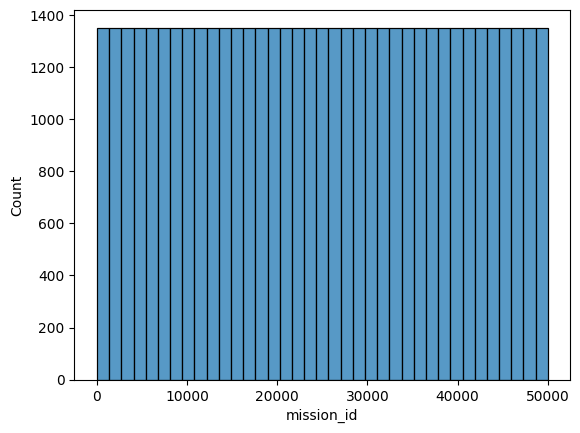

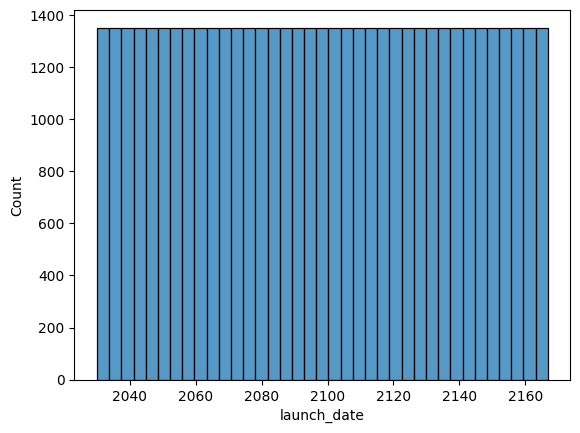

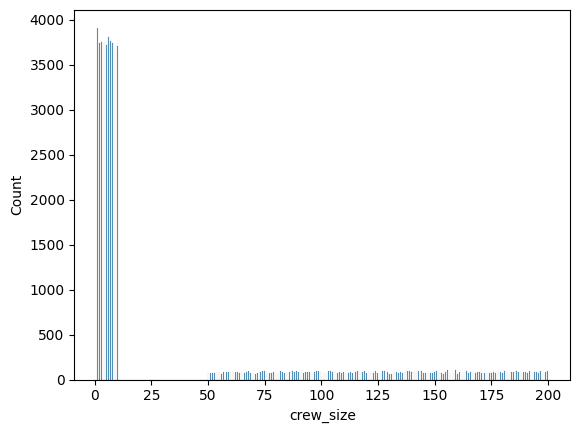

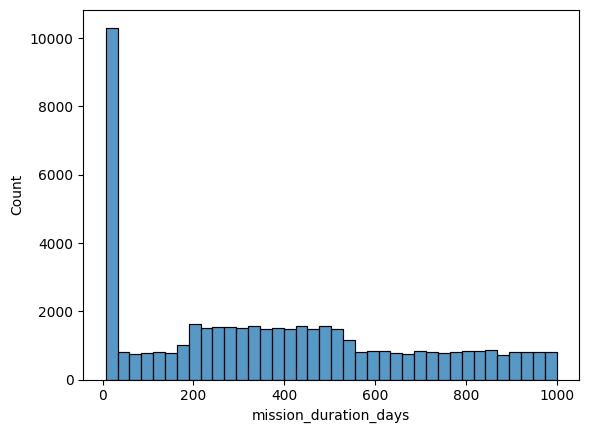

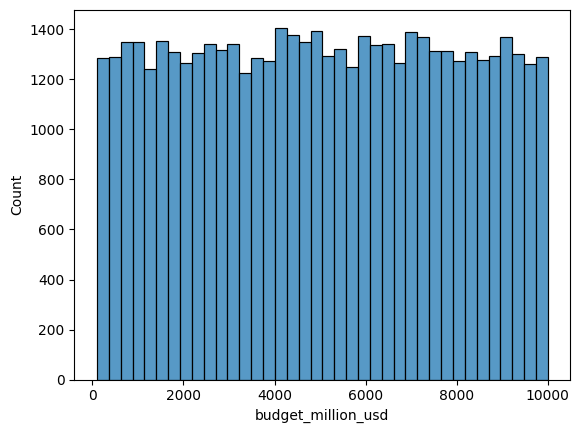

In [29]:
# Assuming false_df is your DataFrame
category_types = ['object', 'bool', 'category']

# Create a list of columns with specified data types
columns_of_interest = df.select_dtypes(include=category_types).columns.tolist()
numeric_cols = df.select_dtypes(exclude=category_types).columns.tolist()

for i in numeric_cols:
  sns.histplot(df[i])
  plt.show()

In [31]:
for i in space_df:
  print(i[0])
  sns.scatterplot(data=df, y=i[1].budget_million_usd, x=i[1].mission_duration_days)
  plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [8]:
passcode_models = ["Starbound Voyager",
                   "Starbound Sentinel",
                   "Pulsar Nomad",
                   "stellar Horizon",
                   "Interstellar Wanderer",
                   "Nova Odyssey"]

In [9]:
import matplotlib.pyplot as plt

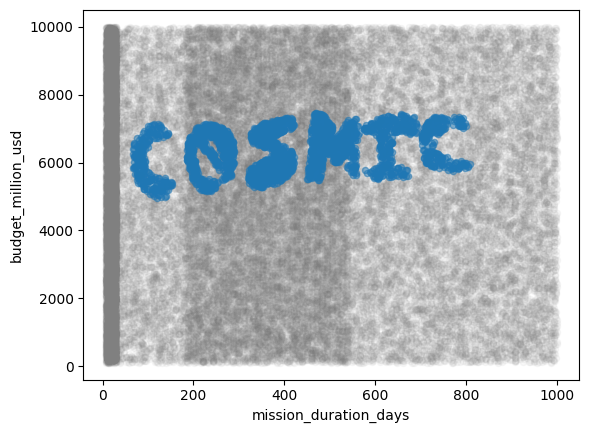

In [13]:
ax = df.plot(
    x="mission_duration_days",
    y="budget_million_usd",
    kind="scatter",
    color="grey",
    alpha=0.05,
)

df.loc[df["spacecraft_model"].isin(passcode_models)].plot(
    x="mission_duration_days",
    y="budget_million_usd",
    kind="scatter",
    ax=ax, alpha=0.5
)
plt.show()

In [ ]:
dest_dur = df.groupby("destination")["spacecraft_model"].value_counts()
dest_dur

destination  spacecraft_model     
Jupiter      Nebula Drifter           215
             Celestial Odyssey        196
             Stellar Horizon          130
             Starbound Voyager        127
             Starbound Sentinel       126
                                     ... 
Venus        Nova Seeker               81
             Stellar Voyager           81
             Astro Drifter             78
             Galactic Trailblazer      78
             Interstellar Explorer     77
Name: count, Length: 484, dtype: int64

In [ ]:
# pd.DataFrame.to_csv(df, "space.csv")

In [ ]:
moondf = df[df["destination"]=='Moon']
moondf.sort_values("budget_million_usd", ascending=False)

,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality
20878,20879,2087-03-01,Moon,Exploration,5,14,Nova Seeker,False,9998.16,High,Active,Resource Extraction,Chemical,Laser,E,Warp Drive,Partial,Planetary Alliance
26371,26372,2102-03-16,Moon,Colonization,71,9,Nova Wanderer,True,9996.17,High,Active,Sample Collection,Nuclear,Radio,A,Fusion Reactor,Partial,Single Nation
44992,44993,2153-03-09,Moon,Exploration,1,16,Nebula Nomad,True,9996.09,Very High,Planned,Terraforming,Chemical,Radio,D,Antimatter Drive,Partial,International
28507,28508,2108-01-20,Moon,Mining,10,14,Starlight Seeker,True,9996.05,Very High,Planned,Habitat Construction,Solar,Laser,E,Impulse Engine,Partial,Single Nation
23709,23710,2094-11-30,Moon,Colonization,156,12,Nebula Mariner,True,9994.91,Very High,Planned,Resource Extraction,Nuclear,Subspace,D,Impulse Engine,Partial,Planetary Alliance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9306,9307,2055-06-25,Moon,Colonization,194,12,Stellar Zephyr,True,102.00,Very High,Planned,Resource Extraction,Ion,Quantum,B,Warp Drive,Partial,Planetary Alliance
13694,13695,2067-06-30,Moon,Colonization,108,15,Interstellar Dreamer,True,101.32,High,Completed,Habitat Construction,Ion,Quantum,A,Impulse Engine,None,International
21957,21958,2090-02-12,Moon,Exploration,5,11,Astro Pathfinder,True,101.09,Very High,Completed,Terraforming,Chemical,Quantum,B,Impulse Engine,Full,Single Nation
18264,18265,2080-01-03,Moon,Exploration,10,11,Interstellar Odyssey,True,100.79,Very High,Active,Resource Extraction,Nuclear,Radio,C,Fusion Reactor,Full,International


destination
Jupiter    518.555255
Mars       359.405269
Moon        18.613918
Saturn     514.806288
Venus      515.581044
Name: mission_duration_days, dtype: float64


<Axes: xlabel='destination', ylabel='mission_duration_days'>

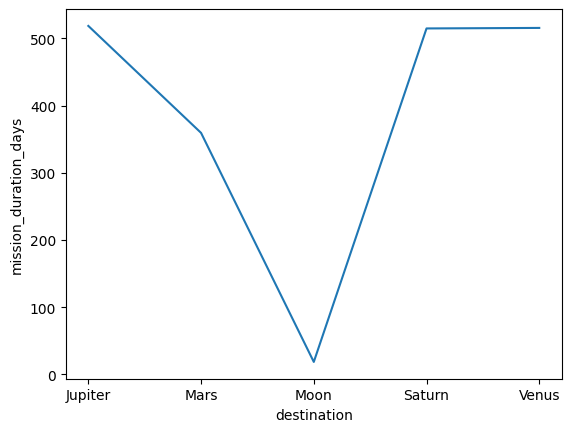

In [ ]:
dest_dur = df.groupby("destination")["mission_duration_days"].mean()

print(dest_dur)
sns.lineplot(dest_dur)

destination
Jupiter    34.783293
Mars       36.025033
Moon       34.588952
Saturn     35.214938
Venus      35.818753
Name: crew_size, dtype: float64


<Axes: xlabel='destination', ylabel='crew_size'>

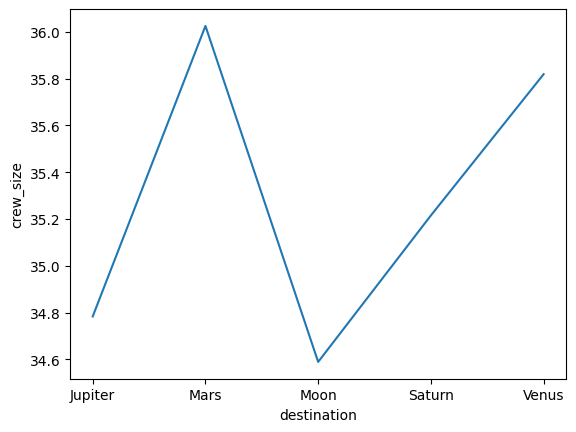

In [ ]:
dest_size = df.groupby("destination")["crew_size"].mean()

print(dest_size)
sns.lineplot(dest_size)

<Axes: xlabel='budget_million_usd', ylabel='Count'>

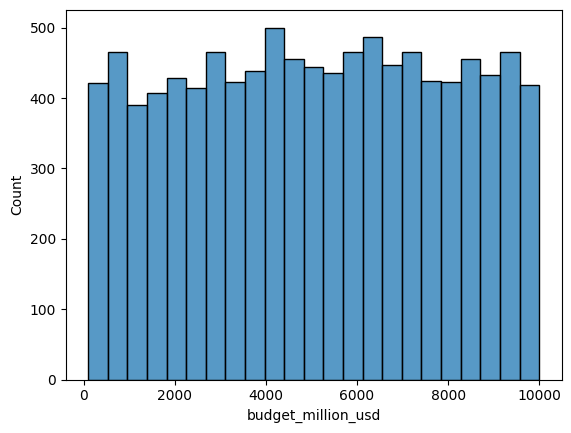

In [ ]:
sns.histplot(moondf.budget_million_usd)

In [ ]:
moondf.spacecraft_model.unique()

array(['Galactic Sentinel', 'Stellar Voyager', 'Celestial Phoenix',
       'Pulsar Dreamer', 'Astro Horizon', 'Astro Horizon II',
       'Astro Pathfinder', 'Cosmic Mariner', 'Cosmic Sentinel',
       'Celestial Dreamer', 'Interstellar Seeker', 'Nova Seeker',
       'Starlight Cruiser', 'Stellar Explorer', 'Stellar Nomad',
       'Stellar Pathfinder', 'Celestial Odyssey', 'Astro Cruiser',
       'Stellar Voyager II', 'Nova Venture', 'Celestial Zephyr',
       'Nebula Pathfinder', 'Galactic Dreamer', 'Quantum Wanderer',
       'Stellar Mariner', 'Cosmic Trailblazer', 'Quantum Voyager',
       'Nebula Voyager', 'Nebula Horizon', 'Cosmic Explorer',
       'Cosmic Voyager', 'Cosmic Horizon', 'Astro Mariner',
       'Celestial Sentinel', 'Quantum Leaper', 'Quantum Seeker',
       'Nebula Navigator', 'Starlight Odyssey', 'Nova Wanderer',
       'Galactic Phoenix', 'Galactic Pioneer', 'Starlight Navigator',
       'Nebula Cruiser', 'Pulsar Zephyr', 'Astro Venture',
       'Interstellar Pionee

In [ ]:
print(moondf.mission_type.value_counts())
print(moondf.mission_success.value_counts())
print(moondf.spacecraft_model.value_counts())
print(moondf.primary_objective.value_counts())
print(moondf.fuel_type.value_counts())
print(moondf.communication_system.value_counts())
print(moondf.life_support_rating.value_counts())
print(moondf.propulsion_system.value_counts())
print(moondf.artificial_gravity.value_counts())
print(moondf.crew_nationality.value_counts())

mission_type
Exploration     2571
Research        2564
Mining          2563
Colonization    2476
Name: count, dtype: int64
mission_success
True     9675
False     499
Name: count, dtype: int64
spacecraft_model
Nebula Drifter          233
Celestial Odyssey       209
Nova Wanderer           135
Interstellar Odyssey    135
Cosmic Zephyr           133
                       ... 
Nova Venture             92
Quantum Voyager          92
Nebula Pathfinder        92
Cosmic Zephyr II         90
Interstellar Seeker      88
Name: count, Length: 92, dtype: int64
primary_objective
Habitat Construction    2612
Sample Collection       2556
Terraforming            2551
Resource Extraction     2455
Name: count, dtype: int64
fuel_type
Nuclear     2603
Chemical    2531
Solar       2529
Ion         2511
Name: count, dtype: int64
communication_system
Quantum     2592
Radio       2566
Laser       2566
Subspace    2450
Name: count, dtype: int64
life_support_rating
E    2090
A    2085
C    2022
B    1994
D    

In [ ]:
moonfalse_df = moondf[moondf["mission_success"] == False]

In [ ]:
moonfalse_df

,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality
35,36,2030-02-05,Moon,Exploration,6,21,Nova Seeker,False,6447.07,Very High,Active,Habitat Construction,Solar,Laser,C,Antimatter Drive,Full,Planetary Alliance
134,135,2030-05-15,Moon,Research,8,17,Cosmic Trailblazer,False,4677.35,Very Low,Active,Sample Collection,Ion,Radio,D,Antimatter Drive,None,Single Nation
293,294,2030-10-21,Moon,Colonization,172,7,Cosmic Nomad,False,8039.42,High,Active,Sample Collection,Nuclear,Quantum,C,Fusion Reactor,None,Single Nation
356,357,2030-12-23,Moon,Exploration,8,23,Starlight Trailblazer,False,7494.64,High,Active,Terraforming,Chemical,Radio,C,Antimatter Drive,Full,International
497,498,2031-05-13,Moon,Mining,2,23,Celestial Seeker,False,8510.70,Very High,Planned,Resource Extraction,Solar,Laser,A,Impulse Engine,Full,Planetary Alliance
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49603,49604,2165-10-23,Moon,Mining,10,18,Stellar Explorer,False,6819.22,Low,Completed,Resource Extraction,Solar,Quantum,A,Antimatter Drive,Full,International
49693,49694,2166-01-21,Moon,Colonization,54,22,Astro Mariner,False,7826.50,High,Completed,Terraforming,Chemical,Radio,E,Antimatter Drive,None,Planetary Alliance
49797,49798,2166-05-05,Moon,Research,8,10,Quantum Leaper,False,9108.57,Low,Active,Habitat Construction,Nuclear,Radio,C,Antimatter Drive,Full,International
49830,49831,2166-06-07,Moon,Research,8,9,Galactic Sentinel,False,117.61,Low,Planned,Terraforming,Solar,Radio,C,Antimatter Drive,Partial,Single Nation


<Axes: >

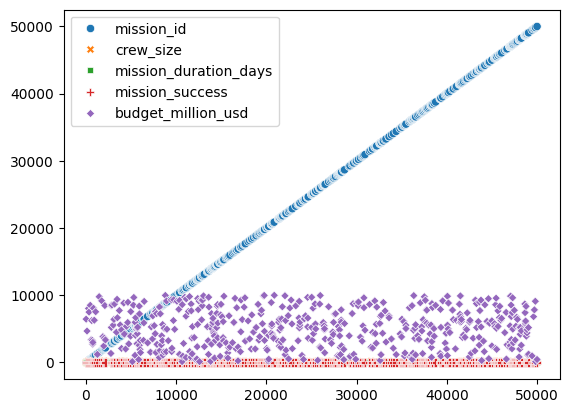

In [ ]:
sns.scatterplot(moonfalse_df)

<Axes: >

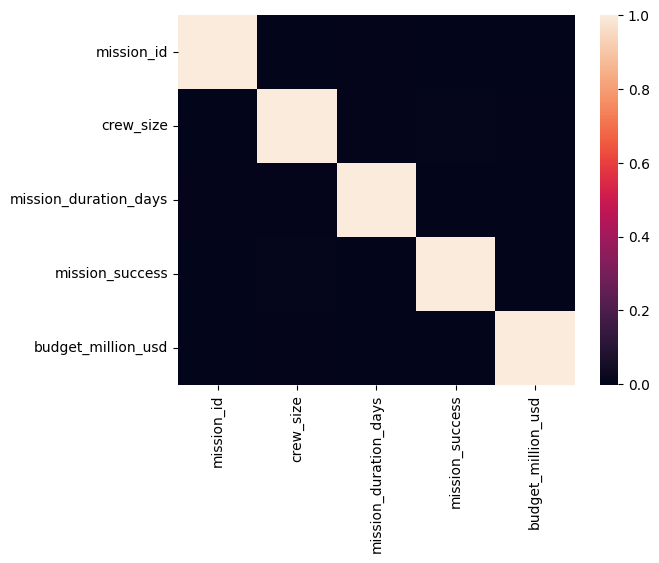

In [ ]:
sns.heatmap(df.corr(numeric_only=True))

In [ ]:
print(moonfalse_df.launch_date)

35      2030-02-05
134     2030-05-15
293     2030-10-21
356     2030-12-23
497     2031-05-13
           ...    
49603   2165-10-23
49693   2166-01-21
49797   2166-05-05
49830   2166-06-07
49988   2166-11-12
Name: launch_date, Length: 499, dtype: datetime64[ns]


<Axes: ylabel='launch_date'>

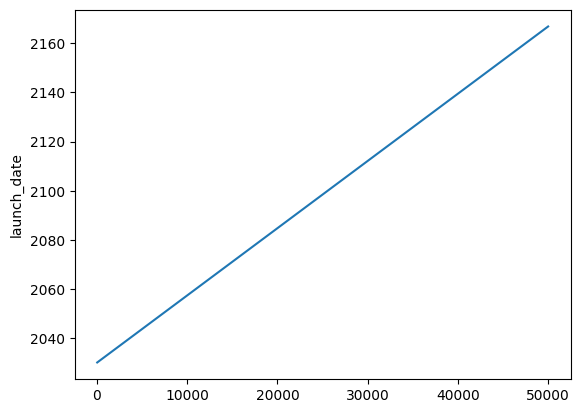

In [ ]:
sns.lineplot(moonfalse_df.launch_date)

<Axes: xlabel='crew_size', ylabel='Count'>

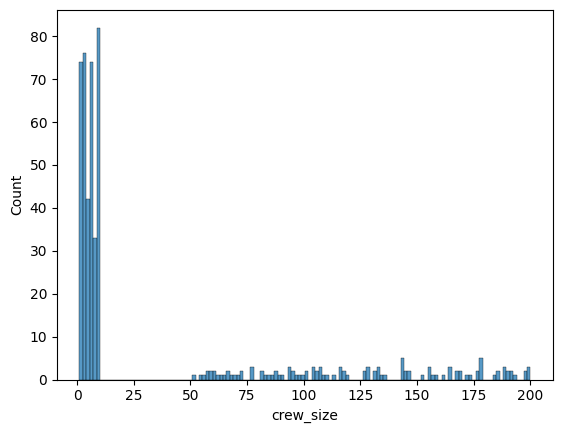

In [ ]:
sns.histplot(moonfalse_df.crew_size)

<Axes: xlabel='budget_million_usd', ylabel='Count'>

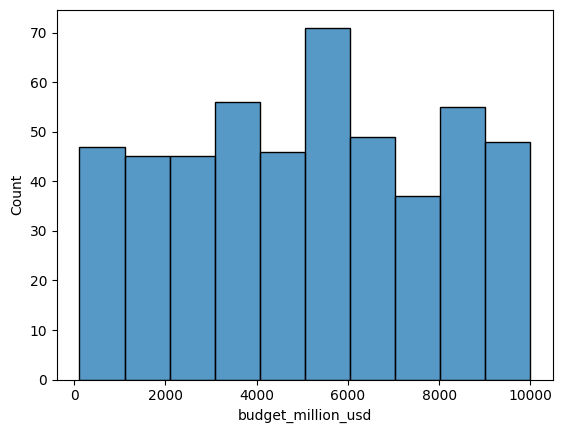

In [ ]:
sns.histplot(moonfalse_df.budget_million_usd)

In [ ]:
df.columns.tolist()

['mission_id',
 'launch_date',
 'destination',
 'mission_type',
 'crew_size',
 'mission_duration_days',
 'spacecraft_model',
 'mission_success',
 'budget_million_usd',
 'scientific_experiments',
 'mission_status',
 'primary_objective',
 'fuel_type',
 'communication_system',
 'life_support_rating',
 'propulsion_system',
 'artificial_gravity',
 'crew_nationality']

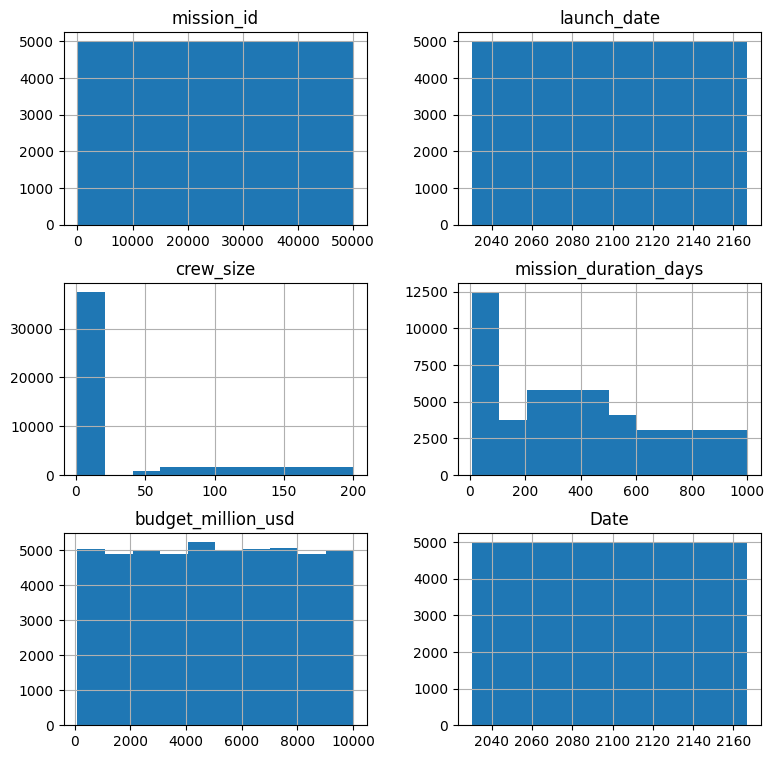

In [ ]:
df.hist(figsize=(9,9))
plt.show()

In [ ]:
df

,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality,Date
0,1,2030-01-01,Venus,Exploration,5,355,Pulsar Dreamer,True,9984.77,Very Low,Active,Sample Collection,Nuclear,Subspace,C,Warp Drive,Partial,Planetary Alliance,2030-01-01
1,2,2030-01-02,Moon,Colonization,83,13,Galactic Sentinel,True,8852.21,Medium,Active,Habitat Construction,Chemical,Subspace,C,Warp Drive,Full,Planetary Alliance,2030-01-02
2,3,2030-01-03,Venus,Mining,8,664,Celestial Phoenix,True,9660.58,Very Low,Planned,Habitat Construction,Chemical,Laser,B,Impulse Engine,None,Planetary Alliance,2030-01-03
3,4,2030-01-04,Saturn,Exploration,8,190,Interstellar Pioneer,True,6879.26,Very High,Active,Sample Collection,Chemical,Quantum,E,Warp Drive,Partial,Single Nation,2030-01-04
4,5,2030-01-05,Saturn,Mining,10,821,Celestial Pioneer,True,2432.28,Medium,Completed,Resource Extraction,Nuclear,Subspace,A,Antimatter Drive,None,Planetary Alliance,2030-01-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,49996,2166-11-19,Venus,Mining,7,536,Interstellar Seeker,True,8109.62,Very High,Completed,Terraforming,Chemical,Radio,D,Antimatter Drive,None,Single Nation,2166-11-19
49996,49997,2166-11-20,Saturn,Research,5,295,Cosmic Trailblazer,True,3442.83,Very Low,Planned,Terraforming,Ion,Subspace,B,Impulse Engine,None,International,2166-11-20
49997,49998,2166-11-21,Mars,Exploration,10,202,Stellar Nomad II,True,9052.08,Medium,Planned,Resource Extraction,Chemical,Subspace,C,Impulse Engine,Full,Planetary Alliance,2166-11-21
49998,49999,2166-11-22,Saturn,Mining,6,785,Galactic Pioneer,False,9410.66,Low,Planned,Sample Collection,Nuclear,Laser,A,Impulse Engine,Full,Single Nation,2166-11-22


In [ ]:
df.iloc[:, 2:]

,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality,Date
0,Venus,Exploration,5,355,Pulsar Dreamer,True,9984.77,Very Low,Active,Sample Collection,Nuclear,Subspace,C,Warp Drive,Partial,Planetary Alliance,2030-01-01
1,Moon,Colonization,83,13,Galactic Sentinel,True,8852.21,Medium,Active,Habitat Construction,Chemical,Subspace,C,Warp Drive,Full,Planetary Alliance,2030-01-02
2,Venus,Mining,8,664,Celestial Phoenix,True,9660.58,Very Low,Planned,Habitat Construction,Chemical,Laser,B,Impulse Engine,None,Planetary Alliance,2030-01-03
3,Saturn,Exploration,8,190,Interstellar Pioneer,True,6879.26,Very High,Active,Sample Collection,Chemical,Quantum,E,Warp Drive,Partial,Single Nation,2030-01-04
4,Saturn,Mining,10,821,Celestial Pioneer,True,2432.28,Medium,Completed,Resource Extraction,Nuclear,Subspace,A,Antimatter Drive,None,Planetary Alliance,2030-01-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,Venus,Mining,7,536,Interstellar Seeker,True,8109.62,Very High,Completed,Terraforming,Chemical,Radio,D,Antimatter Drive,None,Single Nation,2166-11-19
49996,Saturn,Research,5,295,Cosmic Trailblazer,True,3442.83,Very Low,Planned,Terraforming,Ion,Subspace,B,Impulse Engine,None,International,2166-11-20
49997,Mars,Exploration,10,202,Stellar Nomad II,True,9052.08,Medium,Planned,Resource Extraction,Chemical,Subspace,C,Impulse Engine,Full,Planetary Alliance,2166-11-21
49998,Saturn,Mining,6,785,Galactic Pioneer,False,9410.66,Low,Planned,Sample Collection,Nuclear,Laser,A,Impulse Engine,Full,Single Nation,2166-11-22


<Axes: xlabel='count', ylabel='mission_type'>

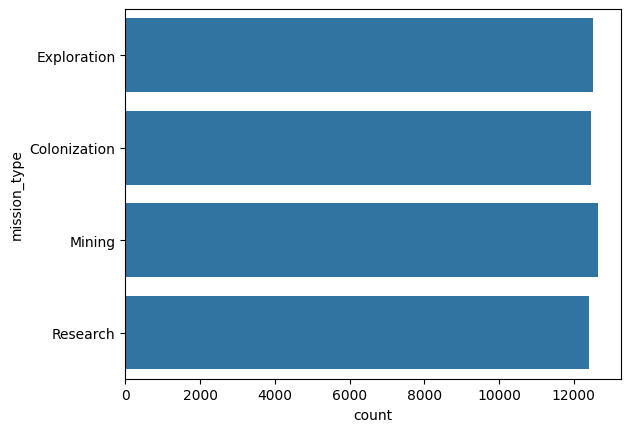

In [ ]:
df.mission_type

<Axes: >

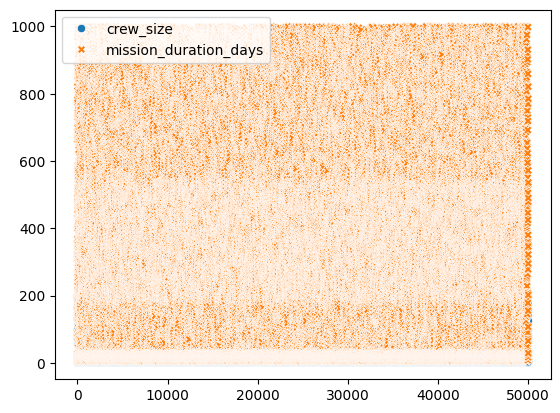

In [ ]:
sns.scatterplot(df.iloc[:, 3:6])

In [ ]:
df.mission_success.value_counts()

,count
mission_success,
True,47535
False,2465


In [ ]:
false_df = df[df["mission_success"] == False]

In [ ]:
false_df.sort_values("crew_size")

,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality,Date
20179,20180,2085-04-01,Venus,Mining,1,106,Nova Explorer,False,2959.20,High,Active,Habitat Construction,Nuclear,Laser,A,Fusion Reactor,Full,Planetary Alliance,2085-04-01
42217,42218,2145-08-03,Venus,Mining,1,124,Stellar Nomad II,False,5712.71,Very High,Active,Sample Collection,Chemical,Laser,C,Fusion Reactor,Full,Planetary Alliance,2145-08-03
26270,26271,2101-12-05,Saturn,Exploration,1,803,Astro Drifter,False,3817.36,Very Low,Completed,Terraforming,Nuclear,Laser,E,Warp Drive,Partial,Planetary Alliance,2101-12-05
6235,6236,2047-01-27,Saturn,Exploration,1,581,Stellar Drifter,False,8152.75,Medium,Planned,Sample Collection,Solar,Radio,A,Fusion Reactor,Partial,International,2047-01-27
42301,42302,2145-10-26,Saturn,Research,1,931,Stellar Voyager II,False,502.64,Medium,Planned,Sample Collection,Solar,Radio,A,Antimatter Drive,Partial,Planetary Alliance,2145-10-26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27607,27608,2105-08-03,Saturn,Colonization,200,897,Stellar Voyager,False,9233.74,High,Active,Sample Collection,Nuclear,Radio,E,Fusion Reactor,Full,International,2105-08-03
25380,25381,2099-06-28,Jupiter,Colonization,200,859,Celestial Navigator,False,7192.22,Very High,Planned,Sample Collection,Ion,Subspace,C,Impulse Engine,Full,International,2099-06-28
3271,3272,2038-12-16,Jupiter,Colonization,200,231,Celestial Navigator,False,3411.06,Very High,Completed,Resource Extraction,Nuclear,Subspace,D,Fusion Reactor,None,Single Nation,2038-12-16
14423,14424,2069-06-28,Mars,Colonization,200,366,Astro Horizon II,False,5244.52,Medium,Planned,Sample Collection,Solar,Radio,B,Warp Drive,Partial,International,2069-06-28


In [ ]:
# conditions

#  (false_df["propulsion_system"]=="Fusion Reactor") & (false_df['primary_objective']=="Resource Extraction")
small_df = false_df[(false_df["crew_size"]<25)& (false_df["mission_duration_days"]<100) & (false_df["destination"]=='Moon')].sort_values("Date")
small_df

,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality,Date
35,36,2030-02-05,Moon,Exploration,6,21,Nova Seeker,False,6447.07,Very High,Active,Habitat Construction,Solar,Laser,C,Antimatter Drive,Full,Planetary Alliance,2030-02-05
134,135,2030-05-15,Moon,Research,8,17,Cosmic Trailblazer,False,4677.35,Very Low,Active,Sample Collection,Ion,Radio,D,Antimatter Drive,None,Single Nation,2030-05-15
356,357,2030-12-23,Moon,Exploration,8,23,Starlight Trailblazer,False,7494.64,High,Active,Terraforming,Chemical,Radio,C,Antimatter Drive,Full,International,2030-12-23
497,498,2031-05-13,Moon,Mining,2,23,Celestial Seeker,False,8510.70,Very High,Planned,Resource Extraction,Solar,Laser,A,Impulse Engine,Full,Planetary Alliance,2031-05-13
588,589,2031-08-12,Moon,Exploration,4,24,Stellar Nomad,False,3367.91,Very Low,Completed,Sample Collection,Chemical,Radio,B,Warp Drive,Full,International,2031-08-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49437,49438,2165-05-10,Moon,Research,5,17,Astro Cruiser,False,980.40,Medium,Active,Terraforming,Solar,Quantum,E,Impulse Engine,Full,Single Nation,2165-05-10
49603,49604,2165-10-23,Moon,Mining,10,18,Stellar Explorer,False,6819.22,Low,Completed,Resource Extraction,Solar,Quantum,A,Antimatter Drive,Full,International,2165-10-23
49797,49798,2166-05-05,Moon,Research,8,10,Quantum Leaper,False,9108.57,Low,Active,Habitat Construction,Nuclear,Radio,C,Antimatter Drive,Full,International,2166-05-05
49830,49831,2166-06-07,Moon,Research,8,9,Galactic Sentinel,False,117.61,Low,Planned,Terraforming,Solar,Radio,C,Antimatter Drive,Partial,Single Nation,2166-06-07


In [ ]:
[small_df["crew_nationality"].value_counts()]

[crew_nationality
 Single Nation         130
 International         127
 Planetary Alliance    124
 Name: count, dtype: int64]

In [ ]:
[small_df["propulsion_system"].value_counts()]

[propulsion_system
 Impulse Engine      108
 Antimatter Drive    105
 Warp Drive           98
 Fusion Reactor       70
 Name: count, dtype: int64]

In [ ]:
[small_df["primary_objective"].value_counts()]

[primary_objective
 Habitat Construction    121
 Terraforming            103
 Sample Collection        90
 Resource Extraction      67
 Name: count, dtype: int64]

<Axes: xlabel='count', ylabel='destination'>

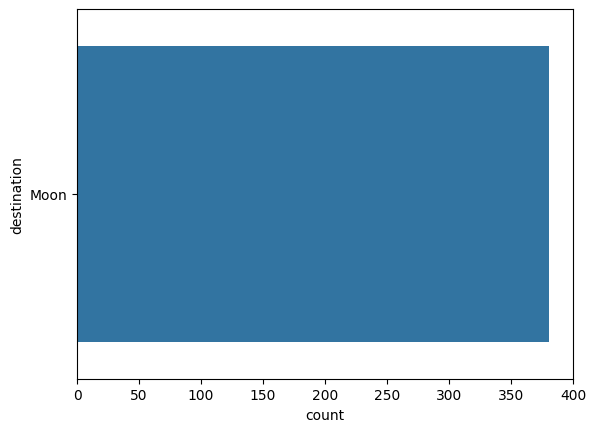

In [ ]:
sns.countplot(small_df.destination)

In [ ]:
[small_df["scientific_experiments"].value_counts()]

[scientific_experiments
 Very High    81
 Low          77
 Very Low     76
 Medium       76
 High         71
 Name: count, dtype: int64]

In [ ]:
# Assuming false_df is your DataFrame
category_types = ['object', 'bool', 'category']

# Create a list of columns with specified data types
columns_of_interest = false_df.select_dtypes(include=category_types).columns.tolist()
numeric_cols = false_df.select_dtypes(exclude=category_types).columns.tolist()

# Display the list
print(columns_of_interest)


['destination', 'mission_type', 'spacecraft_model', 'mission_success', 'scientific_experiments', 'mission_status', 'primary_objective', 'fuel_type', 'communication_system', 'life_support_rating', 'propulsion_system', 'artificial_gravity', 'crew_nationality']


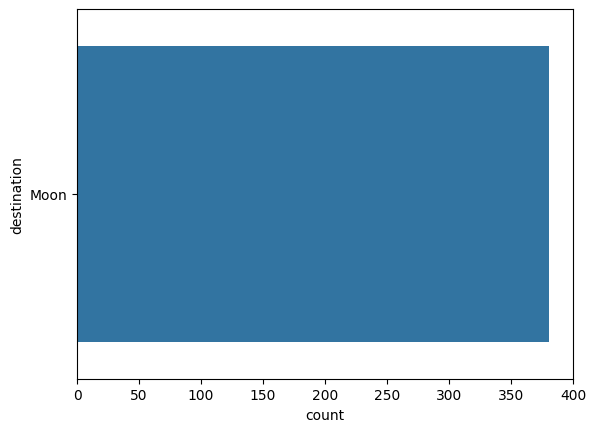

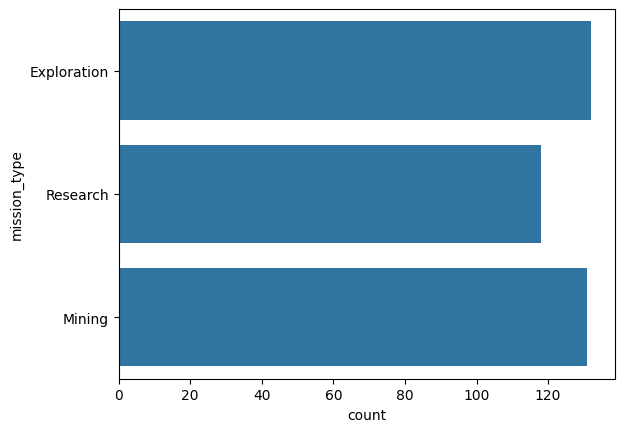

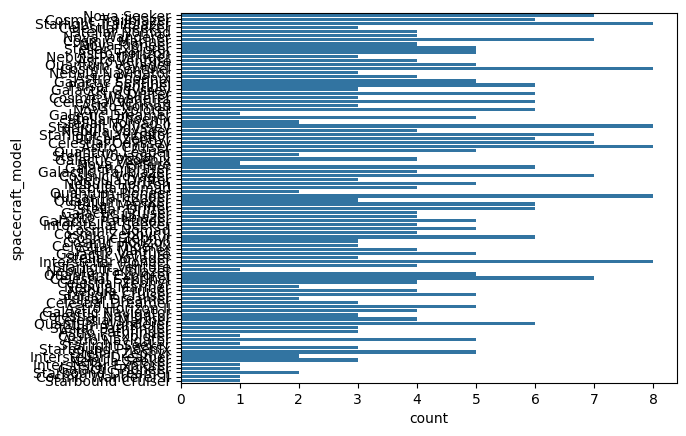

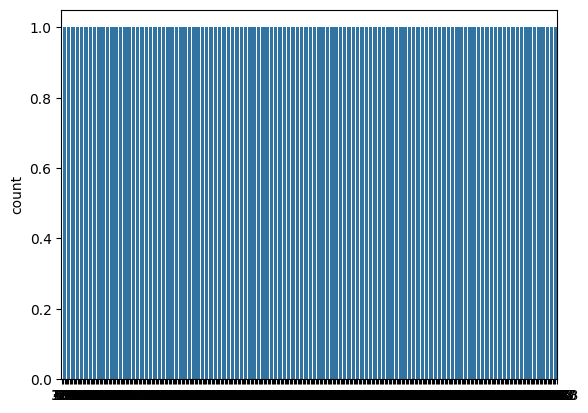

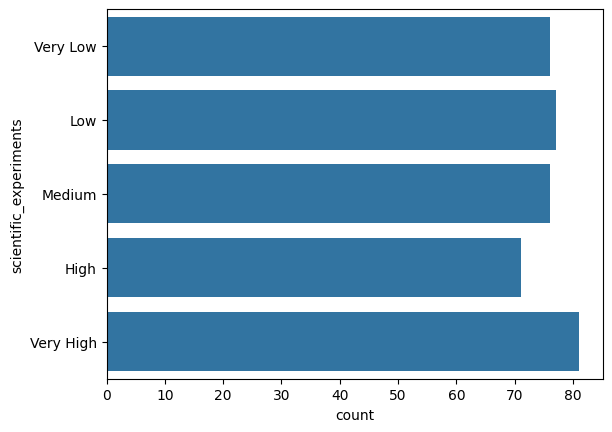

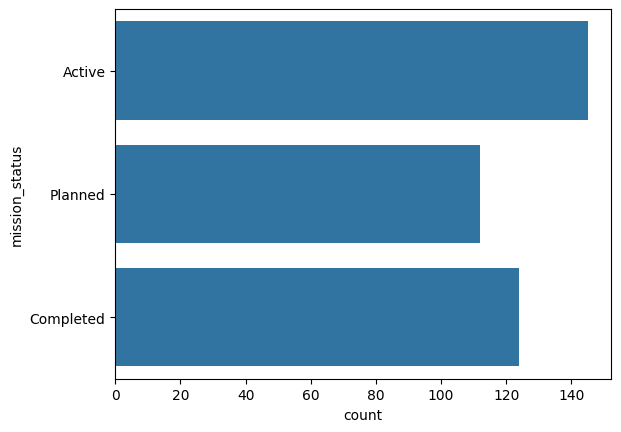

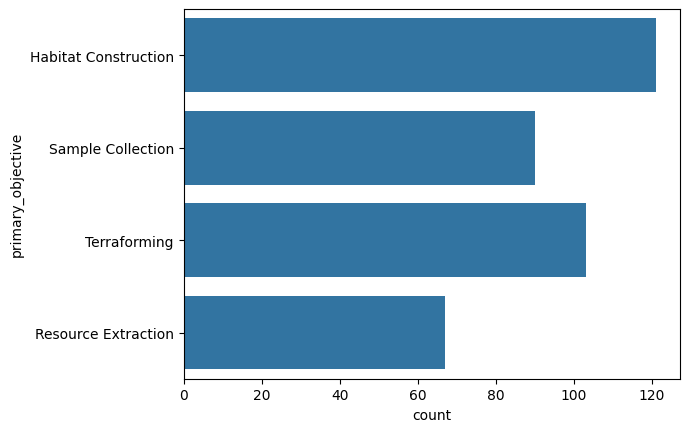

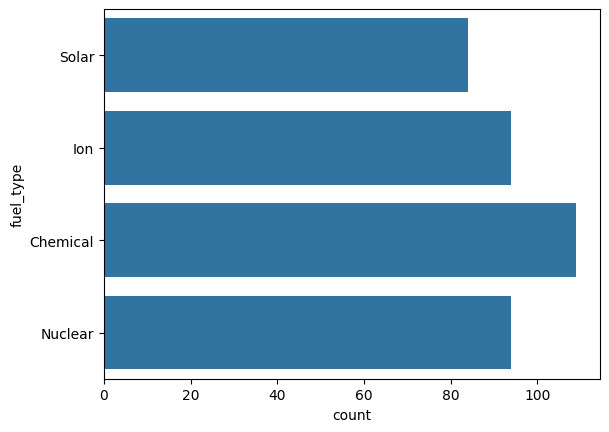

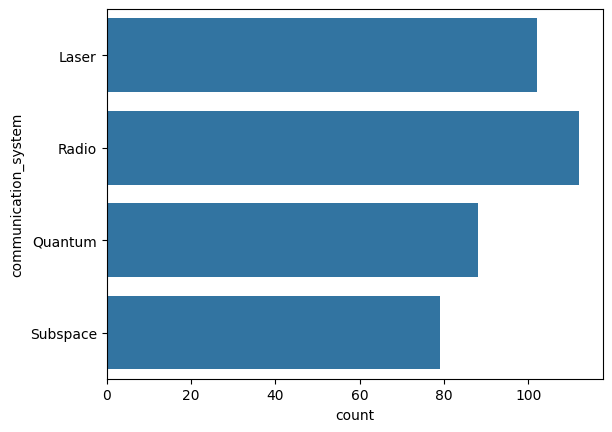

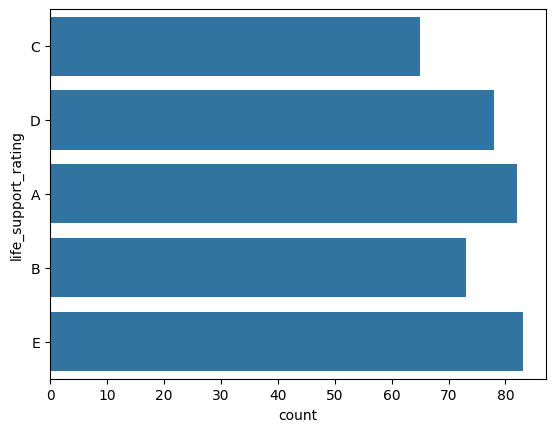

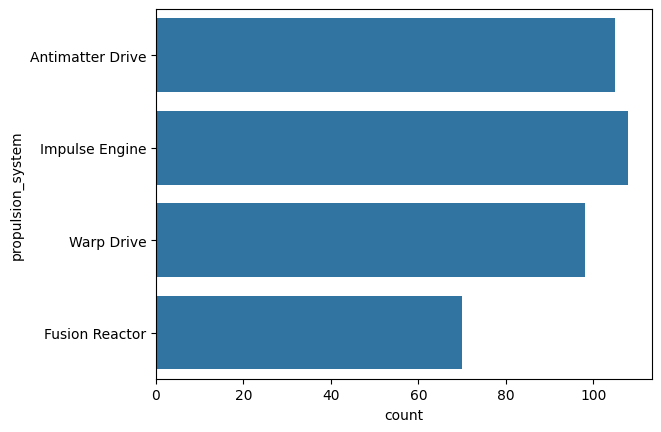

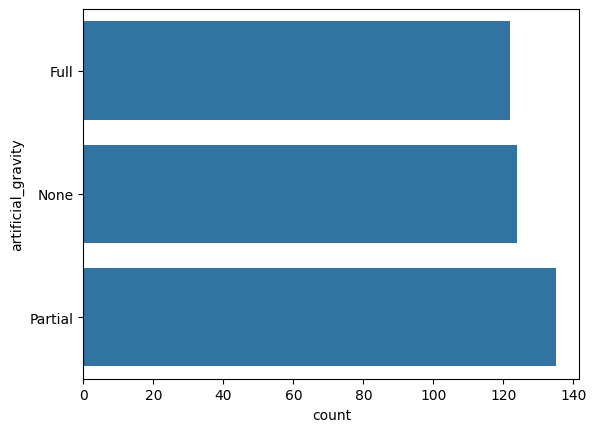

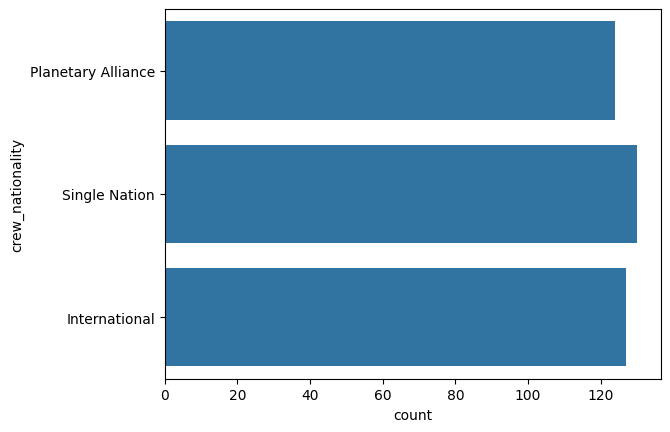

In [ ]:
for i in columns_of_interest:
  sns.countplot(small_df[i])
  plt.show()

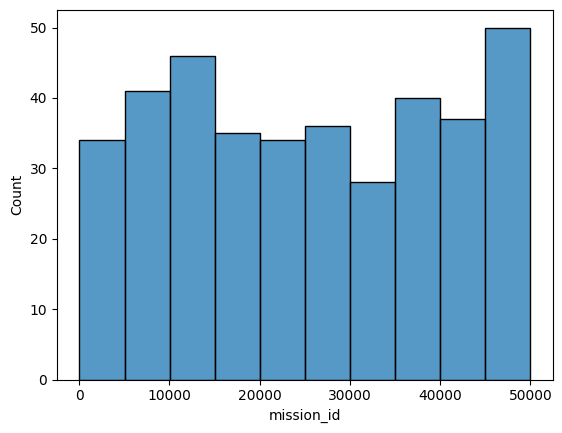

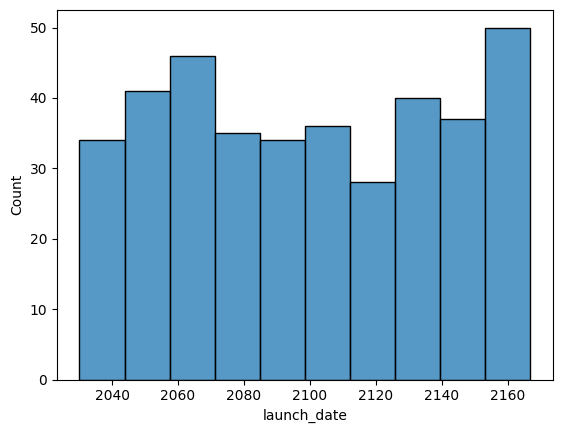

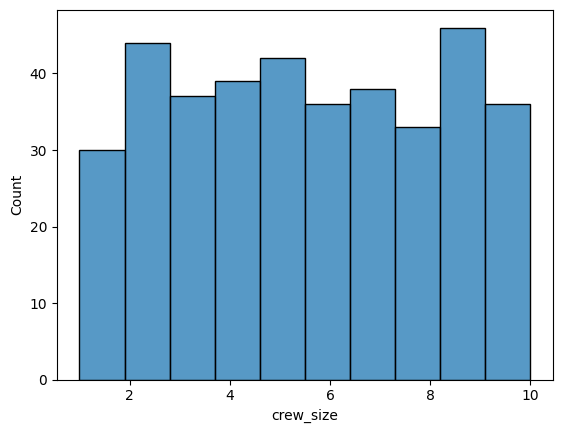

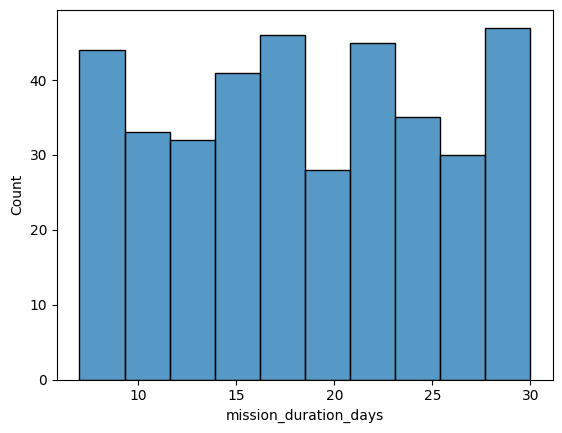

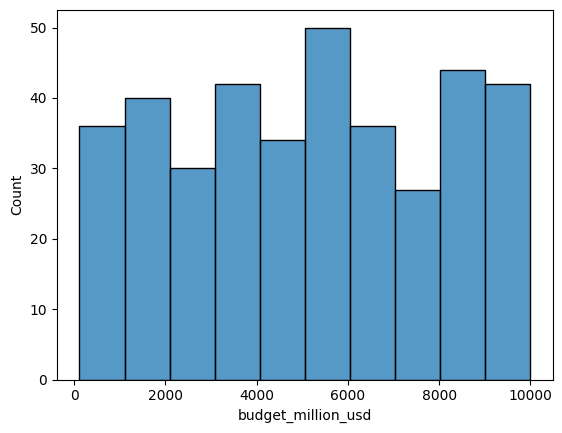

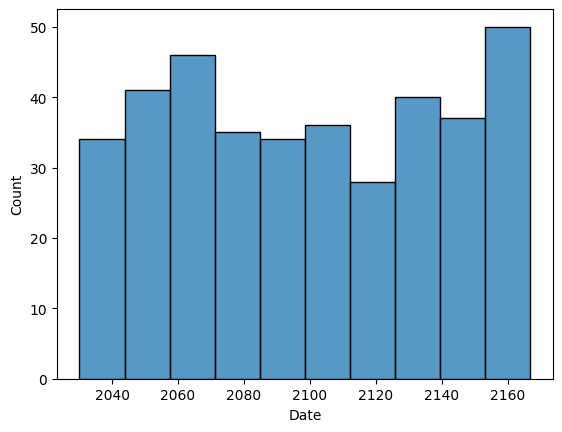

In [ ]:
for i in numeric_cols:
  sns.histplot(small_df[i])
  plt.show()

In [ ]:
# Grouping by 'bear' type and taking the top entry for each group based on 'tune' value
top_bears = false_df.sort_values('crew_size', ascending=True).groupby('destination').head(1)
top_bears = top_bears.sort_values('destination')  # Sorting by bear type for easier visualization
top_bears


,mission_id,launch_date,destination,mission_type,crew_size,mission_duration_days,spacecraft_model,mission_success,budget_million_usd,scientific_experiments,mission_status,primary_objective,fuel_type,communication_system,life_support_rating,propulsion_system,artificial_gravity,crew_nationality,Date
42502,42503,2146-05-15,Jupiter,Mining,1,995,Stellar Mariner,False,7050.46,Very High,Active,Sample Collection,Chemical,Subspace,E,Fusion Reactor,None,International,2146-05-15
32862,32863,2119-12-23,Mars,Mining,1,214,Nebula Navigator,False,1062.83,Medium,Planned,Resource Extraction,Solar,Laser,A,Impulse Engine,Partial,Planetary Alliance,2119-12-23
42911,42912,2147-06-28,Moon,Research,1,8,Cosmic Mariner,False,3614.04,Medium,Planned,Habitat Construction,Nuclear,Subspace,A,Warp Drive,None,Planetary Alliance,2147-06-28
26270,26271,2101-12-05,Saturn,Exploration,1,803,Astro Drifter,False,3817.36,Very Low,Completed,Terraforming,Nuclear,Laser,E,Warp Drive,Partial,Planetary Alliance,2101-12-05
20179,20180,2085-04-01,Venus,Mining,1,106,Nova Explorer,False,2959.20,High,Active,Habitat Construction,Nuclear,Laser,A,Fusion Reactor,Full,Planetary Alliance,2085-04-01


<Axes: xlabel='count', ylabel='life_support_rating'>

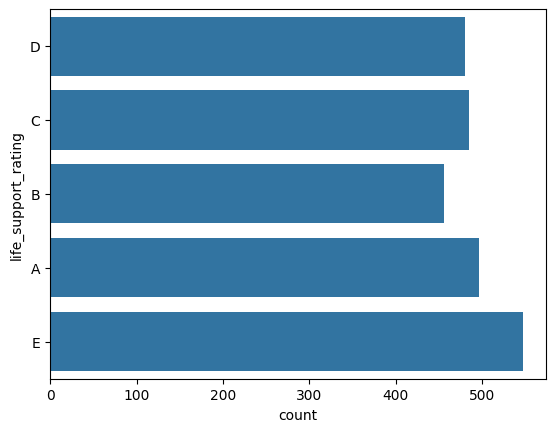

In [ ]:
sns.countplot(false_df["life_support_rating"])

<Axes: xlabel='count', ylabel='fuel_type'>

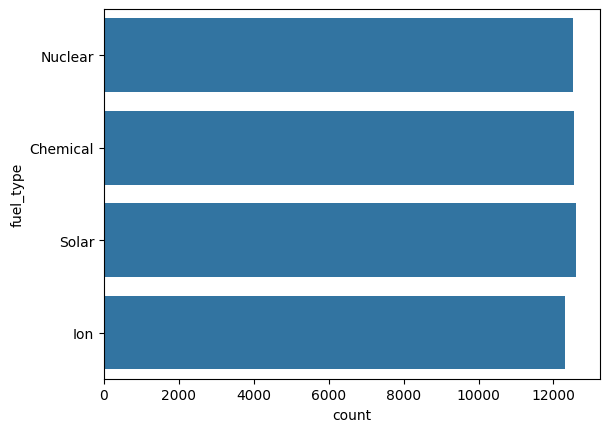

In [ ]:
sns.countplot(df["fuel_type"])

In [ ]:
df["artificial_gravity"].unique()

array(['Partial', 'Full', 'None'], dtype=object)

In [ ]:
for i in df.columns.tolist():
  print(df[i].unique())

[    1     2     3 ... 49998 49999 50000]
<DatetimeArray>
['2030-01-01 00:00:00', '2030-01-02 00:00:00', '2030-01-03 00:00:00',
 '2030-01-04 00:00:00', '2030-01-05 00:00:00', '2030-01-06 00:00:00',
 '2030-01-07 00:00:00', '2030-01-08 00:00:00', '2030-01-09 00:00:00',
 '2030-01-10 00:00:00',
 ...
 '2166-11-14 00:00:00', '2166-11-15 00:00:00', '2166-11-16 00:00:00',
 '2166-11-17 00:00:00', '2166-11-18 00:00:00', '2166-11-19 00:00:00',
 '2166-11-20 00:00:00', '2166-11-21 00:00:00', '2166-11-22 00:00:00',
 '2166-11-23 00:00:00']
Length: 50000, dtype: datetime64[ns]
['Venus' 'Moon' 'Saturn' 'Mars' 'Jupiter']
['Exploration' 'Colonization' 'Mining' 'Research']
[  5  83   8  10   1 130   6 162   9 161   7   3 197 145  97 163  85   2
  73   4 190  62  61  54 156  84 147  68 103 112 118  78 136 169 123 148
 146 135 125  81 183  92 166  89 137  59 111 159 119 155 171 127  60 186
 175 179 154 120  75 134 181 164 167 192 121  56 200  67  96 138  93  63
 172 124 122 176  87 173 102  52 184  86 131 1

In [ ]:
df.columns

Index(['mission_id', 'launch_date', 'destination', 'mission_type', 'crew_size',
       'mission_duration_days', 'spacecraft_model', 'mission_success',
       'budget_million_usd', 'scientific_experiments', 'mission_status',
       'primary_objective', 'fuel_type', 'communication_system',
       'life_support_rating', 'propulsion_system', 'artificial_gravity',
       'crew_nationality'],
      dtype='object')

In [ ]:
df.dtypes

,0
mission_id,int64
launch_date,datetime64[ns]
destination,object
mission_type,object
crew_size,int64
mission_duration_days,int64
spacecraft_model,object
mission_success,bool
budget_million_usd,float64
scientific_experiments,category


destination
Jupiter    518.555255
Mars       359.405269
Moon        18.613918
Saturn     514.806288
Venus      515.581044
Name: mission_duration_days, dtype: float64


<Axes: xlabel='destination', ylabel='mission_duration_days'>

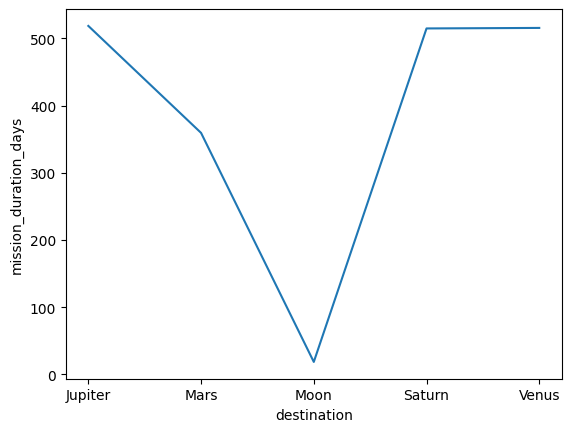

In [ ]:
dest_df = df.groupby("destination")["mission_duration_days"].mean()

print(dest_df)
sns.lineplot(dest_df)

In [ ]:
dest_df = df.groupby("destination")["mission_status"].value_counts()

print(dest_df)
for group in dest_df:
  sns.lineplot(group.mission_status)

destination  mission_status
Jupiter      Active            3402
             Planned           3326
             Completed         3244
Mars         Completed         3338
             Planned           3316
             Active            3253
Moon         Active            3458
             Completed         3374
             Planned           3342
Saturn       Planned           3383
             Completed         3356
             Active            3343
Venus        Completed         3303
             Active            3294
             Planned           3268
Name: count, dtype: int64


AttributeError: 'int' object has no attribute 'mission_status'

destination  life_support_rating
Jupiter      D                      2044
             C                      2022
             A                      1991
             B                      1970
             E                      1945
Mars         C                      2007
             B                      2002
             A                      1983
             E                      1961
             D                      1954
Moon         E                      2090
             A                      2085
             C                      2022
             B                      1994
             D                      1983
Saturn       E                      2131
             A                      2002
             B                      1995
             C                      1994
             D                      1960
Venus        C                      2008
             E                      2001
             A                      1979
             D          

<Axes: xlabel='life_support_rating', ylabel='count'>

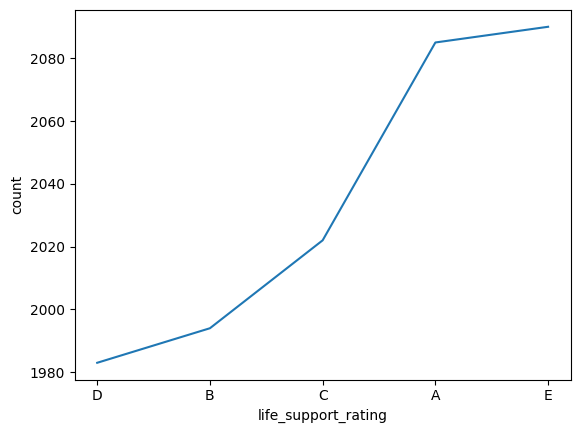

In [ ]:
dest_df = df.groupby("destination")["life_support_rating"].value_counts()

print(dest_df)
sns.lineplot(dest_df.Moon.sort_values("life_support_rating"))

In [ ]:
df.columns

Index(['mission_id', 'launch_date', 'destination', 'mission_type', 'crew_size',
       'mission_duration_days', 'spacecraft_model', 'mission_success',
       'budget_million_usd', 'scientific_experiments', 'mission_status',
       'primary_objective', 'fuel_type', 'communication_system',
       'life_support_rating', 'propulsion_system', 'artificial_gravity',
       'crew_nationality', 'Date'],
      dtype='object')

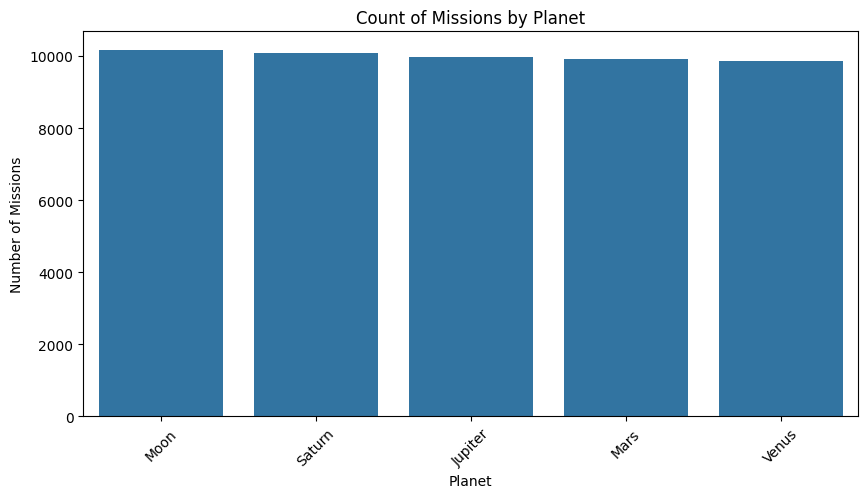

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='destination', order=df['destination'].value_counts().index)
plt.title('Count of Missions by Planet')
plt.xlabel('Planet')
plt.ylabel('Number of Missions')
plt.xticks(rotation=45)
plt.show()


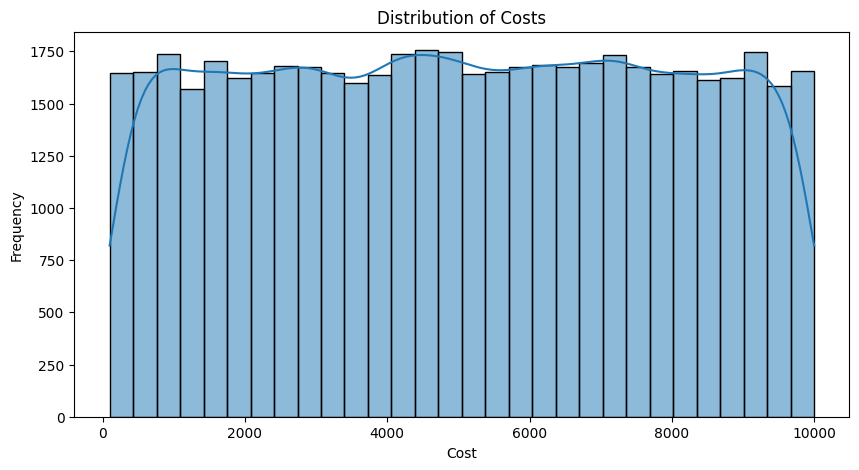

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='budget_million_usd', bins=30, kde=True)
plt.title('Distribution of Costs')
plt.xlabel('Cost')
plt.ylabel('Frequency')
plt.show()


In [ ]:
sns.lineplot(data=df, x='spacecraft_model', )

In [ ]:
import requests


def query(input_data):
    response = requests.post(
        f"{CHALLENGE_URL}/score",
        headers={"X-API-Key": CRUCIBLE_API_KEY},
        json={"data": input_data},
    )
    return response.json()


response = query("moon")
print(response)


{'error': 'Incorrect. Try again.'}
